# 05C — Strict Nested Grouped Temperature Calibration

در `05B` مدل‌های Random Forest با Probability خام ساخته شدند. در این نوت‌بوک فقط Confidence آن Probabilityها را با **Temperature Scaling** اصلاح می‌کنیم.

این مرحله هیچ مداخله‌ای روی Logها اعمال نمی‌کند و هیچ مدل Outer را دوباره آموزش نمی‌دهد.

```text
Frozen outer RF probabilities
        ↓
Fold-specific temperature
        ↓
Calibrated probabilities
```

## اصل ضد Leakage

برای کالیبره‌کردن Outer Fold 1، Labelها و Probabilityهای Fold 1 نباید در Fit کردن Temperature استفاده شوند.

Calibration set Fold 1 به این شکل ساخته می‌شود:

```text
Predict Fold 2 with a model trained on Folds 3,4,5
Predict Fold 3 with a model trained on Folds 2,4,5
Predict Fold 4 with a model trained on Folds 2,3,5
Predict Fold 5 with a model trained on Folds 2,3,4
```

پس هم Outer target fold و هم Inner validation fold از مدلی که آن ردیف را پیش‌بینی می‌کند خارج‌اند.

## Held-out pair trick

برای هر جفت Fold مانند `(1,2)` فقط یک Inner RF می‌سازیم:

```text
Held out: Folds 1 and 2
Train: Folds 3,4,5
```

همان مدل می‌تواند Fold 1 و Fold 2 را بدون Leakage پیش‌بینی کند. در Full فقط 10 جفت Fold برای هر Model variant لازم است.

## Pilot

Pilot فعلی فقط این حالت را اجرا می‌کند:

```text
Raw-8
Target outer fold = 1
Pair models = (1,2), (1,3), (1,4), (1,5)
```

پس از پاس شدن Pilot و اجرای Full نوت‌بوک `05B`، مقدار `RUN_MODE` را روی `full` می‌گذاریم.

In [1]:
import sys, subprocess, importlib.util
packages = {
    'pandas': 'pandas', 'numpy': 'numpy', 'matplotlib': 'matplotlib',
    'sklearn': 'scikit-learn', 'scipy': 'scipy',
    'joblib': 'joblib', 'pyarrow': 'pyarrow'
}
for module, package in packages.items():
    if importlib.util.find_spec(module) is None:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', package])
print('Dependencies are ready.')

Dependencies are ready.


In [2]:
from pathlib import Path
from collections import defaultdict
import gc, hashlib, json, math, platform, time, warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import sklearn
from scipy.optimize import minimize_scalar
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, log_loss

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 300)
pd.set_option('display.max_rows', 300)

EPS = 1e-12
T_MIN, T_MAX = 0.05, 20.0
ECE_BINS = 15
RANDOM_STATE = 142
np.random.seed(RANDOM_STATE)

def sha256_file(path, chunk_size=1024*1024):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        while True:
            chunk = f.read(chunk_size)
            if not chunk:
                break
            h.update(chunk)
    return h.hexdigest()

# 1. تنظیمات

In [3]:
RUN_MODE = 'full'  # pilot | full

ALL_FOLDS = [1, 2, 3, 4, 5]
TARGET_FOLDS = [1] if RUN_MODE == 'pilot' else ALL_FOLDS
ACTIVE_VARIANTS = ['raw8'] if RUN_MODE == 'pilot' else ['raw8', 'core6']
SOURCE_05B_MODE = 'pilot' if RUN_MODE == 'pilot' else 'full'

MODEL_VARIANTS = {
    'raw8': ['GR', 'NPHI', 'RHOB', 'DTC', 'RDEP', 'CALI', 'PEF', 'SP'],
    'core6': ['GR', 'NPHI', 'RHOB', 'DTC', 'RDEP', 'CALI'],
}

RF_PARAMS = {
    'n_estimators': 800,
    'max_depth': 200,
    'min_samples_split': 5,
    'min_samples_leaf': 2,
    'random_state': 142,
    'n_jobs': -1,
    'class_weight': None,
    'bootstrap': True,
    'criterion': 'gini',
}

SKIP_COMPLETED_PAIRS = True
SAVE_INNER_MODELS = False

# Portable project paths (independent of machine-specific Desktop folders).
import os

def _find_stratashift_root():
    start = Path(os.environ.get("STRATASHIFT_REPO_ROOT", Path.cwd())).expanduser().resolve()
    for candidate in (start, *start.parents):
        if (candidate / "notebooks" / "interventions").is_dir() and (candidate / "README.md").is_file():
            return candidate
    raise FileNotFoundError(
        "StrataShift repository root not found. Open Jupyter from inside the repo "
        "or set STRATASHIFT_REPO_ROOT to its absolute path."
    )

REPO_ROOT = _find_stratashift_root()
TRAIN_PATH = Path(os.environ.get(
    "STRATASHIFT_TRAIN_CSV", str(REPO_ROOT / "data" / "raw" / "train.csv")
)).expanduser().resolve()
PROJECT_ROOT = Path(os.environ.get(
    "STRATASHIFT_ARTIFACT_ROOT", str(REPO_ROOT / "artifacts")
)).expanduser().resolve()

PROJECT = PROJECT_ROOT
FOLD_PATH = PROJECT / '01_clean_splits_support' / '10_grouped_5fold_well_assignment.csv'
STAGE_05A = PROJECT / '05A_raw_log_feature_contract' / 'full'
STAGE_05B = PROJECT / '05B_raw_log_RF_grouped_well_CV' / SOURCE_05B_MODE

OUT = PROJECT / '05C_raw_RF_strict_nested_temperature_calibration' / RUN_MODE
PAIR_DIR = OUT / 'inner_pair_predictions'
MODEL_DIR = OUT / 'inner_pair_models'
CAL_DIR = OUT / 'calibration_datasets'
PLOT_DIR = OUT / 'plots'
for p in [OUT, PAIR_DIR, MODEL_DIR, CAL_DIR, PLOT_DIR]:
    p.mkdir(parents=True, exist_ok=True)

required = [
    TRAIN_PATH, FOLD_PATH,
    STAGE_05A / '13_raw_feature_contract_gate.json',
    STAGE_05A / '15_input_file_hashes.json',
    STAGE_05B / '17_stage_gate.json',
    STAGE_05B / '18_run_configuration.json',
]
for variant in ACTIVE_VARIANTS:
    required.append(STAGE_05B / f'16_OOF_predictions_{variant}.parquet')
missing = [str(p) for p in required if not p.exists()]
if missing:
    raise FileNotFoundError('Missing required files:\n' + '\n'.join(missing))

print('RUN_MODE:', RUN_MODE)
print('SOURCE 05B:', STAGE_05B)
print('TARGET_FOLDS:', TARGET_FOLDS)
print('ACTIVE_VARIANTS:', ACTIVE_VARIANTS)
print('OUTPUT:', OUT)

RUN_MODE: full
SOURCE 05B: ${STRATASHIFT_ARTIFACT_ROOT}/05B_raw_log_RF_grouped_well_CV/full
TARGET_FOLDS: [1, 2, 3, 4, 5]
ACTIVE_VARIANTS: ['raw8', 'core6']
OUTPUT: ${STRATASHIFT_ARTIFACT_ROOT}/05C_raw_RF_strict_nested_temperature_calibration/full


# 2. Audit ورودی‌ها

In [4]:
with open(STAGE_05A / '13_raw_feature_contract_gate.json', encoding='utf-8') as f:
    gate05a = json.load(f)
with open(STAGE_05A / '15_input_file_hashes.json', encoding='utf-8') as f:
    hashes05a = json.load(f)
with open(STAGE_05B / '17_stage_gate.json', encoding='utf-8') as f:
    gate05b = json.load(f)
with open(STAGE_05B / '18_run_configuration.json', encoding='utf-8') as f:
    config05b = json.load(f)

current_hashes = {
    'train_csv_sha256': sha256_file(TRAIN_PATH),
    'fold_assignment_sha256': sha256_file(FOLD_PATH),
}

audit = {
    '05A_passed': bool(gate05a.get('overall_raw_feature_contract_passed', False)),
    '05B_passed': bool(gate05b.get('overall_raw_RF_grouped_CV_passed', False)),
    'official_test_unused': bool(gate05b.get('official_test_unused', False)),
    'train_hash_matches': current_hashes['train_csv_sha256'] == hashes05a['train_csv_sha256'],
    'fold_hash_matches': current_hashes['fold_assignment_sha256'] == hashes05a['fold_assignment_sha256'],
    '05B_mode_matches': config05b.get('run_mode') == SOURCE_05B_MODE,
    '05B_probabilities_are_raw': config05b.get('probability_status') == 'raw uncalibrated OOF probabilities',
    'RF_params_match': config05b.get('rf_hyperparameters') == RF_PARAMS,
}
print(json.dumps(audit, indent=2))
if not all(audit.values()):
    raise RuntimeError('Input audit failed.')

{
  "05A_passed": true,
  "05B_passed": true,
  "official_test_unused": true,
  "train_hash_matches": true,
  "fold_hash_matches": true,
  "05B_mode_matches": true,
  "05B_probabilities_are_raw": true,
  "RF_params_match": true
}


# 3. بارگذاری داده و Foldها

In [5]:
def detect_csv(path):
    for enc in ['utf-8', 'latin1', 'cp1252']:
        try:
            with open(path, encoding=enc) as f:
                line = f.readline()
            sep = ';' if ';' in line and ',' not in line else ','
            return sep, enc
        except UnicodeDecodeError:
            pass
    return ',', 'utf-8'

sep, enc = detect_csv(TRAIN_PATH)
train = pd.read_csv(TRAIN_PATH, sep=sep, encoding=enc, low_memory=False)
train['ORIGINAL_ROW_ID'] = np.arange(len(train), dtype=np.int64)

fold_raw = pd.read_csv(FOLD_PATH)
well_col = next(c for c in fold_raw.columns if c.upper() == 'WELL')
fold_col = next(c for c in fold_raw.columns if 'FOLD' in c.upper() and 'SCORE' not in c.upper())
fold_map = (fold_raw[[well_col, fold_col]]
            .rename(columns={well_col: 'WELL', fold_col: 'GROUP_FOLD'})
            .drop_duplicates('WELL'))
fold_map['GROUP_FOLD'] = pd.to_numeric(fold_map['GROUP_FOLD'], errors='raise').astype(int)
train['GROUP_FOLD'] = train['WELL'].map(dict(zip(fold_map['WELL'], fold_map['GROUP_FOLD'])))
if train['GROUP_FOLD'].isna().any():
    raise RuntimeError('Some wells have no fold assignment.')
train['GROUP_FOLD'] = train['GROUP_FOLD'].astype(int)

TARGET = 'FORCE_2020_LITHOFACIES_LITHOLOGY'
CLASSES = np.array([30000,65000,65030,70000,70032,74000,80000,86000,88000,90000,93000,99000], dtype=np.int64)
NAMES = {
    30000:'Sandstone',65000:'Shale',65030:'Sandstone/Shale',70000:'Limestone',
    70032:'Chalk',74000:'Dolomite',80000:'Marl',86000:'Anhydrite',
    88000:'Halite',90000:'Coal',93000:'Basement',99000:'Tuff'
}
CLASS_TO_INDEX = {int(c): i for i, c in enumerate(CLASSES)}
train['LITHOLOGY_CODE'] = pd.to_numeric(train[TARGET], errors='raise').astype(np.int64)
unknown = sorted(set(train['LITHOLOGY_CODE'].unique()) - set(CLASSES.tolist()))
if unknown:
    raise ValueError(f'Unknown classes: {unknown}')

print('Rows:', len(train), 'Wells:', train.WELL.nunique(), 'Folds:', sorted(train.GROUP_FOLD.unique()))

Rows: 1170511 Wells: 98 Folds: [1, 2, 3, 4, 5]


# 4. Cleaning و Feature matrix

In [6]:
def clean_feature(df, feature):
    x = pd.to_numeric(df[feature], errors='coerce').astype(float)
    if feature == 'SP':
        x.loc[np.isclose(x.to_numpy(float), -999.0, rtol=0, atol=1e-12, equal_nan=False)] = np.nan
    x.loc[~np.isfinite(x.to_numpy(float))] = np.nan
    if feature == 'RDEP':
        x.loc[x.notna() & (x <= 0)] = np.nan
    return x.astype(np.float32)

all_features = sorted(set(sum(MODEL_VARIANTS.values(), [])))
missing_features = [f for f in all_features if f not in train.columns]
if missing_features:
    raise KeyError(f'Missing features: {missing_features}')
X_clean = pd.DataFrame({f: clean_feature(train, f) for f in all_features})
display(X_clean.isna().mean().rename('missing_rate'))

CALI    0.075076
DTC     0.069084
GR      0.000000
NPHI    0.346090
PEF     0.426155
RDEP    0.009410
RHOB    0.137777
SP      0.261993
Name: missing_rate, dtype: float64

# 5. توابع Probability و Temperature Scaling

In [7]:
def align_probabilities(local_prob, local_classes):
    out = np.zeros((len(local_prob), len(CLASSES)), dtype=np.float64)
    for j, c in enumerate(local_classes):
        out[:, CLASS_TO_INDEX[int(c)]] = local_prob[:, j]
    sums = out.sum(axis=1, keepdims=True)
    if np.any(sums <= 0):
        raise RuntimeError('Invalid probability row.')
    return out / sums

def apply_temperature(prob, T):
    if not np.isfinite(T) or T <= 0:
        raise ValueError(f'Invalid temperature {T}')
    z = np.log(np.clip(np.asarray(prob, float), EPS, 1.0)) / float(T)
    z -= z.max(axis=1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(axis=1, keepdims=True)

def multiclass_brier(y, prob):
    onehot = np.zeros_like(prob)
    idx = np.array([CLASS_TO_INDEX[int(c)] for c in y])
    onehot[np.arange(len(y)), idx] = 1.0
    return float(np.mean(np.sum((prob-onehot)**2, axis=1)))

def ece_score(y, prob, bins=15, return_bins=False):
    pred = CLASSES[np.argmax(prob, axis=1)]
    conf = np.max(prob, axis=1)
    correct = (pred == y).astype(float)
    edges = np.linspace(0, 1, bins+1)
    ece, rows = 0.0, []
    for b in range(bins):
        lo, hi = edges[b], edges[b+1]
        mask = (conf >= lo) & ((conf <= hi) if b == bins-1 else (conf < hi))
        n = int(mask.sum())
        if n:
            mc, ac = float(conf[mask].mean()), float(correct[mask].mean())
            gap = abs(mc-ac)
            ece += n/len(y)*gap
        else:
            mc = ac = gap = np.nan
        rows.append({'bin':b,'lower':lo,'upper':hi,'count':n,'mean_confidence':mc,'accuracy':ac,'gap':gap})
    return (float(ece), pd.DataFrame(rows)) if return_bins else float(ece)

def metrics(y, prob):
    pred = CLASSES[np.argmax(prob, axis=1)]
    present = np.unique(y)
    return {
        'rows': int(len(y)),
        'accuracy': float(accuracy_score(y, pred)),
        'balanced_accuracy': float(balanced_accuracy_score(y, pred)),
        'macro_f1_global_12': float(f1_score(y, pred, labels=CLASSES, average='macro', zero_division=0)),
        'macro_f1_present_classes': float(f1_score(y, pred, labels=present, average='macro', zero_division=0)),
        'log_loss': float(log_loss(y, prob, labels=CLASSES)),
        'multiclass_brier': multiclass_brier(y, prob),
        'ece_15': ece_score(y, prob, ECE_BINS),
        'mean_confidence': float(np.max(prob, axis=1).mean()),
    }

def fit_temperature(y, prob):
    def objective(log_t):
        return log_loss(y, apply_temperature(prob, np.exp(log_t)), labels=CLASSES)
    grid = np.linspace(np.log(T_MIN), np.log(T_MAX), 161)
    losses = np.array([objective(g) for g in grid])
    i = int(np.argmin(losses))
    lo, hi = grid[max(0,i-2)], grid[min(len(grid)-1,i+2)]
    opt = minimize_scalar(objective, bounds=(lo,hi), method='bounded', options={'xatol':1e-8,'maxiter':500})
    return float(np.exp(opt.x)), bool(opt.success), str(opt.message), pd.DataFrame({'temperature':np.exp(grid),'nll':losses})

# 6. ساخت Inner held-out-pair predictionها

In [8]:
required_pairs = sorted({tuple(sorted((target, inner))) for target in TARGET_FOLDS for inner in ALL_FOLDS if inner != target})
expected_pairs = 4 if RUN_MODE == 'pilot' else 10
if len(required_pairs) != expected_pairs:
    raise RuntimeError(f'Unexpected pair count: {len(required_pairs)}')
print('Required pairs:', required_pairs)

pair_frames = defaultdict(dict)
pair_audits, pair_manifest = [], []
prob_cols = [f'prob_{c}' for c in CLASSES]

for variant in ACTIVE_VARIANTS:
    features = MODEL_VARIANTS[variant]
    print('\nVARIANT:', variant)
    for a, b in required_pairs:
        prefix = f'{variant}__heldout_pair_{a}_{b}'
        pred_path = PAIR_DIR / f'{prefix}__predictions.parquet'
        meta_path = PAIR_DIR / f'{prefix}__metadata.json'
        model_path = MODEL_DIR / f'{prefix}__RF.joblib'
        imp_path = MODEL_DIR / f'{prefix}__imputer.joblib'

        if SKIP_COMPLETED_PAIRS and pred_path.exists() and meta_path.exists():
            with open(meta_path, encoding='utf-8') as f:
                meta = json.load(f)
            if not meta.get('pair_gate_passed', False):
                raise RuntimeError(f'Cached pair failed: {prefix}')
            frame = pd.read_parquet(pred_path)
            pair_frames[variant][(a,b)] = frame
            pair_audits.append(meta['audit'])
            pair_manifest.append({'variant':variant,'fold_a':a,'fold_b':b,'path':str(pred_path),'sha256':sha256_file(pred_path),'status':'cache'})
            print(prefix, 'loaded')
            continue

        started = time.time()
        hold_mask = train.GROUP_FOLD.isin([a,b]).to_numpy()
        tr_mask = ~hold_mask
        train_folds = sorted(train.loc[tr_mask,'GROUP_FOLD'].unique().tolist())
        expected_train_folds = sorted(set(ALL_FOLDS)-{a,b})
        if train_folds != expected_train_folds:
            raise RuntimeError(f'Training fold mismatch for {prefix}')
        tr_wells = set(train.loc[tr_mask,'WELL'])
        ho_wells = set(train.loc[hold_mask,'WELL'])
        overlap = tr_wells & ho_wells
        if overlap:
            raise RuntimeError(f'Well overlap for {prefix}')

        imputer = SimpleImputer(strategy='median')
        Xtr = imputer.fit_transform(X_clean.loc[tr_mask, features].to_numpy(np.float32)).astype(np.float32, copy=False)
        ytr = train.loc[tr_mask,'LITHOLOGY_CODE'].to_numpy(np.int64)
        model = RandomForestClassifier(**RF_PARAMS)
        model.fit(Xtr, ytr)

        parts = []
        for prediction_fold in [a,b]:
            pmask = (train.GROUP_FOLD == prediction_fold).to_numpy()
            Xp = imputer.transform(X_clean.loc[pmask, features].to_numpy(np.float32)).astype(np.float32, copy=False)
            p = align_probabilities(model.predict_proba(Xp), model.classes_)
            part = train.loc[pmask, ['ORIGINAL_ROW_ID','WELL','GROUP_FOLD','LITHOLOGY_CODE']].copy()
            part = part.rename(columns={'GROUP_FOLD':'prediction_fold','LITHOLOGY_CODE':'true_code'})
            part['model_variant'] = variant
            part['heldout_fold_a'] = a
            part['heldout_fold_b'] = b
            for j,c in enumerate(CLASSES):
                part[f'prob_{c}'] = p[:,j].astype(np.float32)
            parts.append(part)
            del Xp, p, part
            gc.collect()

        frame = pd.concat(parts, ignore_index=True).sort_values(['prediction_fold','ORIGINAL_ROW_ID']).reset_index(drop=True)
        P = frame[prob_cols].to_numpy(float)
        audit_pair = {
            'model_variant':variant,'heldout_fold_a':a,'heldout_fold_b':b,
            'training_folds':train_folds,
            'training_folds_correct':train_folds == expected_train_folds,
            'train_heldout_wells_disjoint':len(overlap)==0,
            'both_heldout_folds_predicted':sorted(frame.prediction_fold.unique().tolist()) == [a,b],
            'row_ids_unique':not frame.ORIGINAL_ROW_ID.duplicated().any(),
            'probabilities_finite':bool(np.isfinite(P).all()),
            'probabilities_in_range':bool((P>=-1e-8).all() and (P<=1+1e-8).all()),
            'probability_rows_sum_to_one':bool(np.allclose(P.sum(axis=1),1,rtol=1e-6,atol=1e-6)),
            'imputer_fit_on_pair_training_only':True,
            'model_fit_on_pair_training_only':True,
            'official_test_unused':True,
            'seconds':float(time.time()-started),
        }
        audit_pair['pair_gate_passed'] = bool(all([
            audit_pair['training_folds_correct'], audit_pair['train_heldout_wells_disjoint'],
            audit_pair['both_heldout_folds_predicted'], audit_pair['row_ids_unique'],
            audit_pair['probabilities_finite'], audit_pair['probabilities_in_range'],
            audit_pair['probability_rows_sum_to_one'], audit_pair['official_test_unused']
        ]))
        if not audit_pair['pair_gate_passed']:
            raise RuntimeError(f'Pair gate failed: {prefix}')

        frame.to_parquet(pred_path, index=False)
        if SAVE_INNER_MODELS:
            joblib.dump(model, model_path, compress=1)
            joblib.dump(imputer, imp_path, compress=1)
        meta = {
            'model_variant':variant,'heldout_fold_a':a,'heldout_fold_b':b,
            'feature_list':features,'rf_hyperparameters':RF_PARAMS,
            'model_classes':[int(x) for x in model.classes_],
            'imputer_statistics':{f:float(imputer.statistics_[i]) for i,f in enumerate(features)},
            'audit':audit_pair,'pair_gate_passed':audit_pair['pair_gate_passed'],
            'inner_models_saved':SAVE_INNER_MODELS,
        }
        with open(meta_path,'w',encoding='utf-8') as f:
            json.dump(meta,f,indent=2,ensure_ascii=False)
        pair_frames[variant][(a,b)] = frame
        pair_audits.append(audit_pair)
        pair_manifest.append({'variant':variant,'fold_a':a,'fold_b':b,'path':str(pred_path),'sha256':sha256_file(pred_path),'status':'built'})
        print(prefix, 'passed in', round(audit_pair['seconds'],1), 's')
        del Xtr, ytr, model, imputer, frame, P
        gc.collect()

Required pairs: [(1, 2), (1, 3), (1, 4), (1, 5), (2, 3), (2, 4), (2, 5), (3, 4), (3, 5), (4, 5)]

VARIANT: raw8
raw8__heldout_pair_1_2 passed in 192.8 s
raw8__heldout_pair_1_3 passed in 198.7 s
raw8__heldout_pair_1_4 passed in 190.0 s
raw8__heldout_pair_1_5 passed in 191.5 s
raw8__heldout_pair_2_3 passed in 190.5 s
raw8__heldout_pair_2_4 passed in 191.4 s
raw8__heldout_pair_2_5 passed in 187.2 s
raw8__heldout_pair_3_4 passed in 192.5 s
raw8__heldout_pair_3_5 passed in 195.1 s
raw8__heldout_pair_4_5 passed in 188.9 s

VARIANT: core6
core6__heldout_pair_1_2 passed in 193.5 s
core6__heldout_pair_1_3 passed in 204.0 s
core6__heldout_pair_1_4 passed in 194.5 s
core6__heldout_pair_1_5 passed in 200.8 s
core6__heldout_pair_2_3 passed in 195.1 s
core6__heldout_pair_2_4 passed in 192.4 s
core6__heldout_pair_2_5 passed in 190.4 s
core6__heldout_pair_3_4 passed in 195.8 s
core6__heldout_pair_3_5 passed in 197.3 s
core6__heldout_pair_4_5 passed in 195.8 s


# 7. ساخت Strict calibration set و Fit کردن Temperature

In [9]:
calibration_audits = []
temperature_rows = []
fold_metric_rows = []
objective_frames = []
reliability_frames = []
calibrated_oof_parts = defaultdict(list)
calibration_sets = {}

for variant in ACTIVE_VARIANTS:
    raw_oof = pd.read_parquet(STAGE_05B / f'16_OOF_predictions_{variant}.parquet')
    for target_fold in TARGET_FOLDS:
        parts = []
        for inner_fold in ALL_FOLDS:
            if inner_fold == target_fold:
                continue
            pair = tuple(sorted((target_fold, inner_fold)))
            pframe = pair_frames[variant][pair]
            part = pframe.loc[pframe.prediction_fold == inner_fold].copy()
            part['target_outer_fold'] = target_fold
            part['inner_validation_fold'] = inner_fold
            parts.append(part)
        cal = pd.concat(parts, ignore_index=True).sort_values('ORIGINAL_ROW_ID').reset_index(drop=True)
        expected_mask = train.GROUP_FOLD != target_fold
        expected_ids = set(train.loc[expected_mask,'ORIGINAL_ROW_ID'])
        observed_ids = set(cal.ORIGINAL_ROW_ID)
        Pcal = cal[prob_cols].to_numpy(float)
        audit_cal = {
            'model_variant':variant,'target_outer_fold':target_fold,
            'calibration_rows':len(cal),'expected_rows':int(expected_mask.sum()),
            'row_count_correct':len(cal)==int(expected_mask.sum()),
            'calibration_wells':int(cal.WELL.nunique()),
            'expected_wells':int(train.loc[expected_mask,'WELL'].nunique()),
            'well_count_correct':cal.WELL.nunique()==train.loc[expected_mask,'WELL'].nunique(),
            'row_ids_unique':not cal.ORIGINAL_ROW_ID.duplicated().any(),
            'row_id_set_exact':observed_ids==expected_ids,
            'target_fold_absent_from_calibration_rows':bool((cal.prediction_fold != target_fold).all()),
            'four_inner_folds_present':sorted(cal.inner_validation_fold.unique().tolist()) == sorted(set(ALL_FOLDS)-{target_fold}),
            'probabilities_finite':bool(np.isfinite(Pcal).all()),
            'probability_rows_sum_to_one':bool(np.allclose(Pcal.sum(axis=1),1,rtol=1e-6,atol=1e-6)),
            'official_test_unused':True,
        }
        audit_cal['calibration_gate_passed'] = bool(all([
            audit_cal['row_count_correct'],audit_cal['well_count_correct'],audit_cal['row_ids_unique'],
            audit_cal['row_id_set_exact'],audit_cal['target_fold_absent_from_calibration_rows'],
            audit_cal['four_inner_folds_present'],audit_cal['probabilities_finite'],
            audit_cal['probability_rows_sum_to_one'],audit_cal['official_test_unused']
        ]))
        if not audit_cal['calibration_gate_passed']:
            raise RuntimeError(f'Calibration set gate failed: {variant}, fold {target_fold}')
        cal.to_parquet(CAL_DIR / f'{variant}__target_fold_{target_fold}__strict_inner_OOF.parquet', index=False)
        calibration_sets[(variant,target_fold)] = cal
        calibration_audits.append(audit_cal)

        ycal = cal.true_code.to_numpy(np.int64)
        T, opt_success, opt_message, curve = fit_temperature(ycal, Pcal)
        Pcal_scaled = apply_temperature(Pcal, T)
        m_cal_raw, m_cal_scaled = metrics(ycal,Pcal), metrics(ycal,Pcal_scaled)

        outer = raw_oof.loc[raw_oof.outer_fold == target_fold].copy()
        if outer.empty:
            raise RuntimeError(f'05B OOF missing fold {target_fold} for {variant}')
        yout = outer.true_code.to_numpy(np.int64)
        Praw = outer[prob_cols].to_numpy(float)
        Pscaled = apply_temperature(Praw,T)
        m_raw, m_scaled = metrics(yout,Praw), metrics(yout,Pscaled)
        pred_raw = CLASSES[np.argmax(Praw,axis=1)]
        pred_scaled = CLASSES[np.argmax(Pscaled,axis=1)]
        true_idx = np.array([CLASS_TO_INDEX[int(c)] for c in yout])
        ptrue_raw = Praw[np.arange(len(yout)),true_idx]
        ptrue_scaled = Pscaled[np.arange(len(yout)),true_idx]

        outer['temperature'] = T
        outer['raw_true_class_probability_replayed'] = ptrue_raw.astype(np.float32)
        outer['calibrated_true_class_probability'] = ptrue_scaled.astype(np.float32)
        outer['raw_row_log_loss_replayed'] = (-np.log(np.clip(ptrue_raw,EPS,1))).astype(np.float32)
        outer['calibrated_row_log_loss'] = (-np.log(np.clip(ptrue_scaled,EPS,1))).astype(np.float32)
        outer['calibrated_predicted_code'] = pred_scaled.astype(np.int64)
        outer['calibrated_predicted_name'] = outer.calibrated_predicted_code.map(NAMES)
        for j,c in enumerate(CLASSES):
            outer[f'cal_prob_{c}'] = Pscaled[:,j].astype(np.float32)
        calibrated_oof_parts[variant].append(outer)

        temperature_rows.append({
            'model_variant':variant,'target_outer_fold':target_fold,'temperature':T,
            'temperature_positive_finite':bool(np.isfinite(T) and T>0),
            'temperature_inside_bounds':bool(T_MIN <= T <= T_MAX),
            'optimization_success':opt_success,'optimization_message':opt_message,
            'calibration_rows':len(cal),'calibration_wells':cal.WELL.nunique(),
            'calibration_raw_log_loss':m_cal_raw['log_loss'],
            'calibration_calibrated_log_loss':m_cal_scaled['log_loss'],
            'calibration_log_loss_improvement':m_cal_raw['log_loss']-m_cal_scaled['log_loss'],
            'calibration_raw_brier':m_cal_raw['multiclass_brier'],
            'calibration_calibrated_brier':m_cal_scaled['multiclass_brier'],
            'calibration_raw_ece_15':m_cal_raw['ece_15'],
            'calibration_calibrated_ece_15':m_cal_scaled['ece_15'],
            'calibration_nll_not_worse':m_cal_scaled['log_loss'] <= m_cal_raw['log_loss'] + 1e-10,
            'outer_rows':len(outer),'outer_wells':outer.WELL.nunique(),
            'outer_argmax_unchanged':bool(np.array_equal(pred_raw,pred_scaled)),
            'outer_raw_log_loss':m_raw['log_loss'],'outer_calibrated_log_loss':m_scaled['log_loss'],
            'outer_raw_brier':m_raw['multiclass_brier'],'outer_calibrated_brier':m_scaled['multiclass_brier'],
            'outer_raw_ece_15':m_raw['ece_15'],'outer_calibrated_ece_15':m_scaled['ece_15'],
        })
        for status,m in [('raw',m_raw),('calibrated',m_scaled)]:
            row = {'model_variant':variant,'target_outer_fold':target_fold,'probability_status':status,'temperature':1.0 if status=='raw' else T}
            row.update(m)
            fold_metric_rows.append(row)
        curve['model_variant'] = variant
        curve['target_outer_fold'] = target_fold
        objective_frames.append(curve)
        for status,P in [('raw',Praw),('calibrated',Pscaled)]:
            _, bins = ece_score(yout,P,ECE_BINS,return_bins=True)
            bins['model_variant'] = variant
            bins['target_outer_fold'] = target_fold
            bins['probability_status'] = status
            reliability_frames.append(bins)

        print(f'{variant}, target fold {target_fold}: T={T:.6f}, outer LL {m_raw["log_loss"]:.6f} -> {m_scaled["log_loss"]:.6f}')
        del Pcal,Pcal_scaled,Praw,Pscaled,outer,cal
        gc.collect()

raw8, target fold 1: T=1.034485, outer LL 0.863874 -> 0.863188
raw8, target fold 2: T=0.993024, outer LL 0.996871 -> 0.991891
raw8, target fold 3: T=1.020554, outer LL 0.992526 -> 0.975262
raw8, target fold 4: T=1.120219, outer LL 1.023197 -> 1.012277
raw8, target fold 5: T=1.033628, outer LL 0.837070 -> 0.836534
core6, target fold 1: T=1.295672, outer LL 0.946012 -> 0.917943
core6, target fold 2: T=1.288428, outer LL 1.100025 -> 1.027476
core6, target fold 3: T=1.260103, outer LL 1.108528 -> 1.047242
core6, target fold 4: T=1.415372, outer LL 1.092389 -> 1.045992
core6, target fold 5: T=1.294732, outer LL 0.901553 -> 0.889121


# 8. تجمیع OOF و Metricها

In [10]:
temperature_df = pd.DataFrame(temperature_rows)
fold_metrics_df = pd.DataFrame(fold_metric_rows)
objective_df = pd.concat(objective_frames, ignore_index=True)
reliability_df = pd.concat(reliability_frames, ignore_index=True)
calibrated_oof = {}
pooled_rows, well_rows, replay_rows = [], [], []

for variant in ACTIVE_VARIANTS:
    df = pd.concat(calibrated_oof_parts[variant], ignore_index=True).sort_values('ORIGINAL_ROW_ID').reset_index(drop=True)
    calibrated_oof[variant] = df
    y = df.true_code.to_numpy(np.int64)
    raw_cols = prob_cols
    cal_cols = [f'cal_prob_{c}' for c in CLASSES]
    for status, cols in [('raw',raw_cols),('calibrated',cal_cols)]:
        m = metrics(y,df[cols].to_numpy(float))
        m.update({'model_variant':variant,'probability_status':status,'outer_folds':df.outer_fold.nunique(),'wells':df.WELL.nunique()})
        pooled_rows.append(m)
    for well,wdf in df.groupby('WELL'):
        yw = wdf.true_code.to_numpy(np.int64)
        for status, cols in [('raw',raw_cols),('calibrated',cal_cols)]:
            m = metrics(yw,wdf[cols].to_numpy(float))
            m.update({'model_variant':variant,'probability_status':status,'WELL':well,'outer_fold':int(wdf.outer_fold.iloc[0])})
            well_rows.append(m)
    replay_rows.append({
        'model_variant':variant,'rows':len(df),
        'true_probability_replay_matches':bool(np.allclose(df.true_class_probability,df.raw_true_class_probability_replayed,rtol=1e-6,atol=1e-6)),
        'row_log_loss_replay_matches':bool(np.allclose(df.row_log_loss,df.raw_row_log_loss_replayed,rtol=1e-5,atol=1e-5)),
        'predicted_labels_unchanged':bool((df.predicted_code == df.calibrated_predicted_code).all()),
        'accuracy_unchanged':bool(np.mean(df.predicted_code==df.true_code) == np.mean(df.calibrated_predicted_code==df.true_code)),
        'max_abs_true_probability_replay_difference':float(np.max(np.abs(df.true_class_probability-df.raw_true_class_probability_replayed))),
        'max_abs_row_log_loss_replay_difference':float(np.max(np.abs(df.row_log_loss-df.raw_row_log_loss_replayed))),
    })

pooled_df = pd.DataFrame(pooled_rows)
well_df = pd.DataFrame(well_rows)
replay_df = pd.DataFrame(replay_rows)
well_balanced_df = (well_df.groupby(['model_variant','probability_status'],as_index=False)
    .agg(wells=('WELL','nunique'),well_balanced_accuracy=('accuracy','mean'),
         well_balanced_log_loss=('log_loss','mean'),well_balanced_brier=('multiclass_brier','mean'),
         well_balanced_ece_15=('ece_15','mean'),median_well_log_loss=('log_loss','median'),
         worst_well_log_loss=('log_loss','max')))

display(temperature_df)
display(pooled_df)
display(well_balanced_df)
display(replay_df)

,model_variant,target_outer_fold,temperature,temperature_positive_finite,temperature_inside_bounds,optimization_success,optimization_message,calibration_rows,calibration_wells,calibration_raw_log_loss,calibration_calibrated_log_loss,calibration_log_loss_improvement,calibration_raw_brier,calibration_calibrated_brier,calibration_raw_ece_15,calibration_calibrated_ece_15,calibration_nll_not_worse,outer_rows,outer_wells,outer_argmax_unchanged,outer_raw_log_loss,outer_calibrated_log_loss,outer_raw_brier,outer_calibrated_brier,outer_raw_ece_15,outer_calibrated_ece_15
0,raw8,1,1.034485,True,True,True,Solution found.,937837,78,0.982421,0.971342,0.011079,0.449149,0.449780,0.023077,0.026926,True,232674,20,True,0.863874,0.863188,0.392489,0.393440,0.044574,0.050716
1,raw8,2,0.993024,True,True,True,Solution found.,934306,78,0.926423,0.919523,0.006900,0.428281,0.428101,0.030758,0.029554,True,236205,20,True,0.996871,0.991891,0.462545,0.462625,0.032360,0.033488
2,raw8,3,1.020554,True,True,True,Solution found.,939933,77,0.967438,0.952577,0.014862,0.433169,0.433835,0.047216,0.049579,True,230578,21,True,0.992526,0.975262,0.444898,0.445292,0.032062,0.034712
3,raw8,4,1.120219,True,True,True,Solution found.,933379,81,1.078297,1.030360,0.047937,0.435805,0.440722,0.038992,0.064749,True,237132,17,True,1.023197,1.012277,0.477447,0.479440,0.020928,0.036115
4,raw8,5,1.033628,True,True,True,Solution found.,936589,78,0.993503,0.981356,0.012147,0.455537,0.456111,0.022459,0.028335,True,233922,20,True,0.837070,0.836534,0.399541,0.401648,0.061677,0.071928
5,core6,1,1.295672,True,True,True,Solution found.,937837,78,1.066670,1.012481,0.054188,0.464389,0.464222,0.043406,0.038996,True,232674,20,True,0.946012,0.917943,0.403011,0.408064,0.034367,0.064433
6,core6,2,1.288428,True,True,True,Solution found.,934306,78,1.061590,1.001322,0.060268,0.440222,0.444441,0.025515,0.050720,True,236205,20,True,1.100025,1.027476,0.480741,0.475045,0.068999,0.045920
7,core6,3,1.260103,True,True,True,Solution found.,939933,77,1.030430,0.983527,0.046903,0.443238,0.445826,0.028105,0.049706,True,230578,21,True,1.108528,1.047242,0.475554,0.473671,0.049663,0.032478
8,core6,4,1.415372,True,True,True,Solution found.,933379,81,1.178113,1.068330,0.109783,0.455408,0.461151,0.036037,0.069203,True,237132,17,True,1.092389,1.045992,0.474644,0.481465,0.033672,0.066016
9,core6,5,1.294732,True,True,True,Solution found.,936589,78,1.084261,1.032025,0.052236,0.470267,0.471042,0.039393,0.045774,True,233922,20,True,0.901553,0.889121,0.409597,0.419130,0.019911,0.079045


,rows,accuracy,balanced_accuracy,macro_f1_global_12,macro_f1_present_classes,log_loss,multiclass_brier,ece_15,mean_confidence,model_variant,probability_status,outer_folds,wells
0,1170511,0.695989,0.311005,0.342382,0.342382,0.942976,0.435571,0.027674,0.678116,raw8,raw,5,98
1,1170511,0.695989,0.311005,0.342382,0.342382,0.936114,0.436678,0.036151,0.666329,raw8,calibrated,5,98
2,1170511,0.683319,0.306784,0.331009,0.331009,1.029874,0.448815,0.033539,0.716820,core6,raw,5,98
3,1170511,0.683319,0.306784,0.331009,0.331009,0.985698,0.451586,0.050557,0.639134,core6,calibrated,5,98


,model_variant,probability_status,wells,well_balanced_accuracy,well_balanced_log_loss,well_balanced_brier,well_balanced_ece_15,median_well_log_loss,worst_well_log_loss
0,core6,calibrated,98,0.678493,0.970987,0.450527,0.112474,0.860288,2.284635
1,core6,raw,98,0.678493,1.008803,0.449092,0.096728,0.856354,2.724017
2,raw8,calibrated,98,0.688209,0.931521,0.438581,0.118673,0.828046,2.223721
3,raw8,raw,98,0.688209,0.937194,0.437704,0.115137,0.826322,2.258033


,model_variant,rows,true_probability_replay_matches,row_log_loss_replay_matches,predicted_labels_unchanged,accuracy_unchanged,max_abs_true_probability_replay_difference,max_abs_row_log_loss_replay_difference
0,raw8,1170511,True,True,True,True,0.0,4.768372e-07
1,core6,1170511,True,True,True,True,0.0,9.536743e-07


# 9. نمودارها

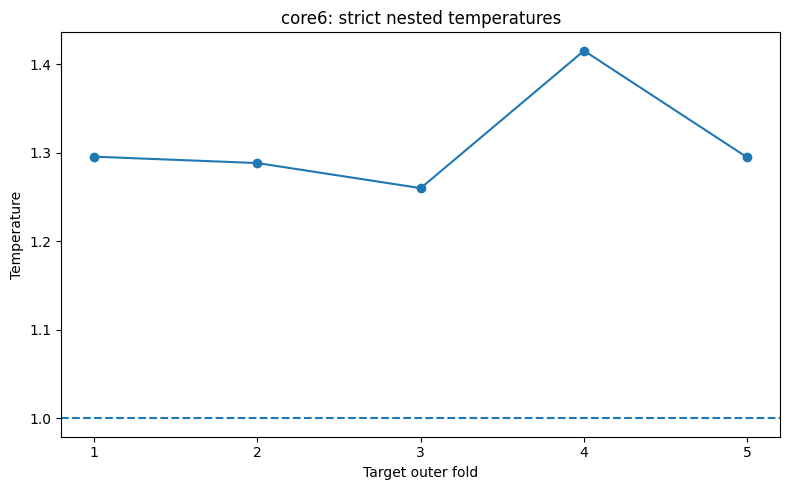

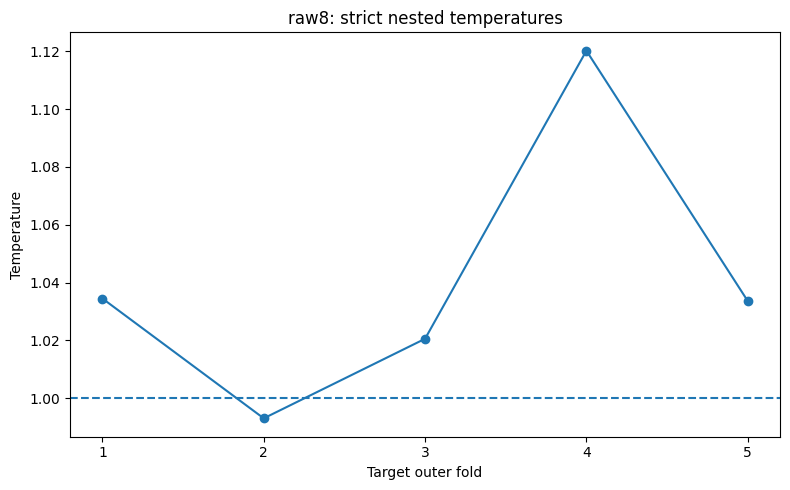

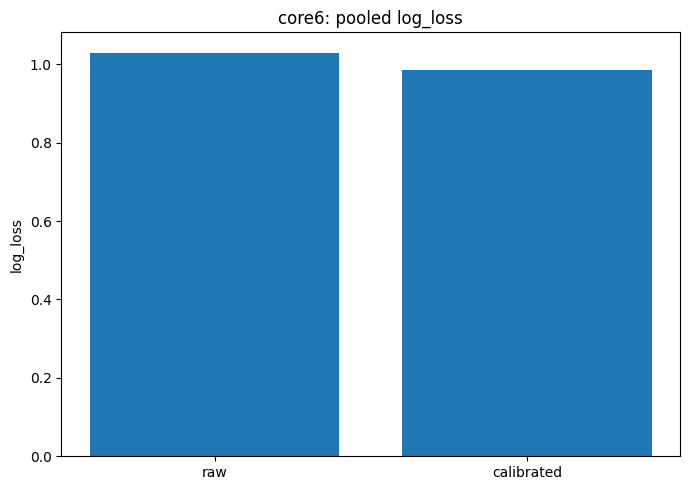

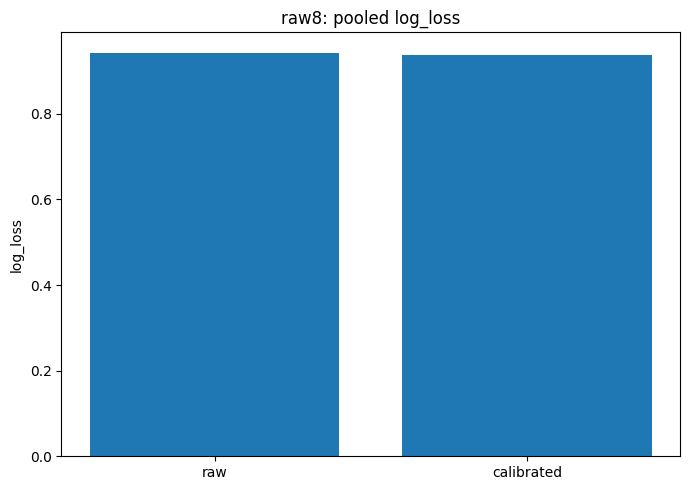

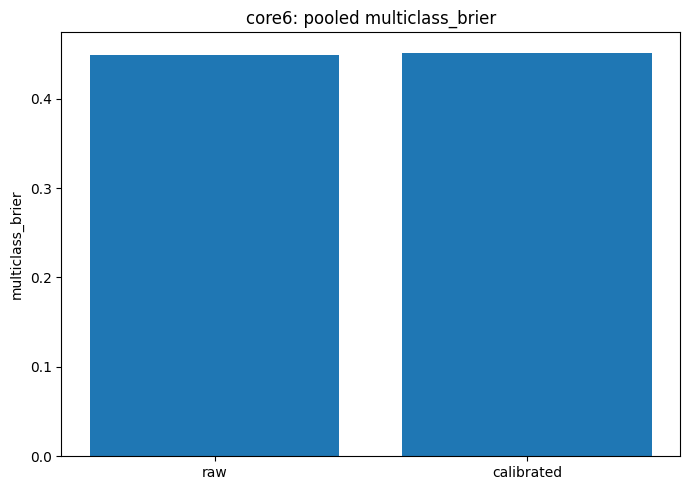

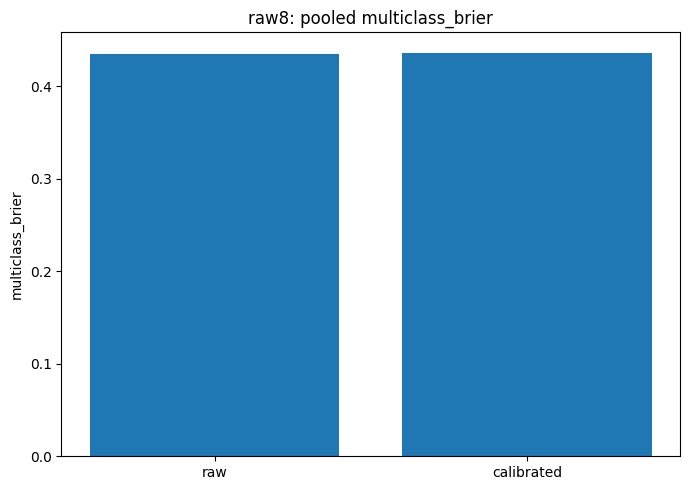

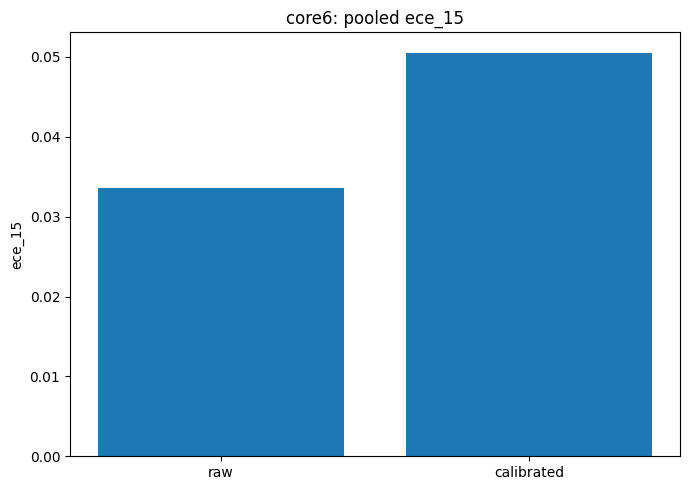

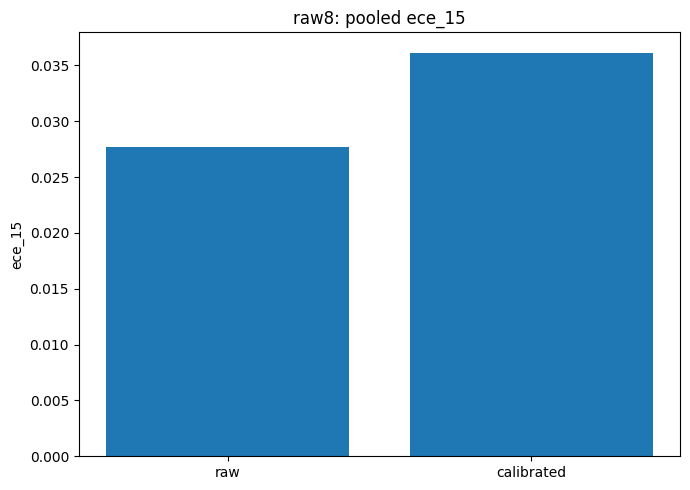

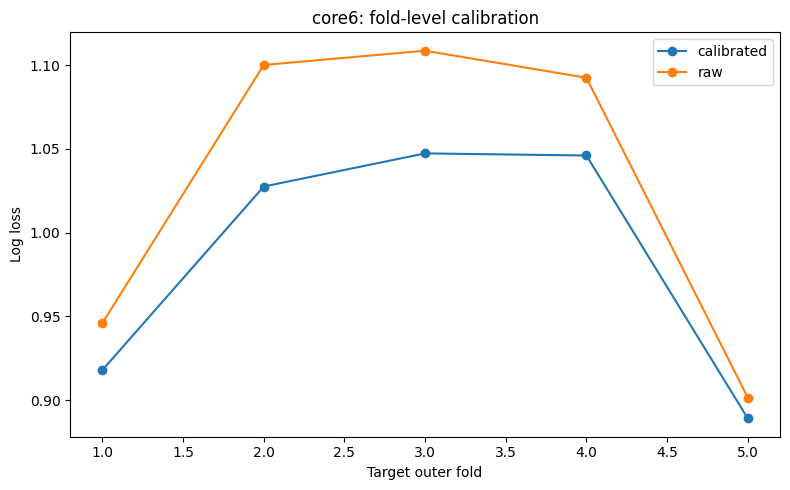

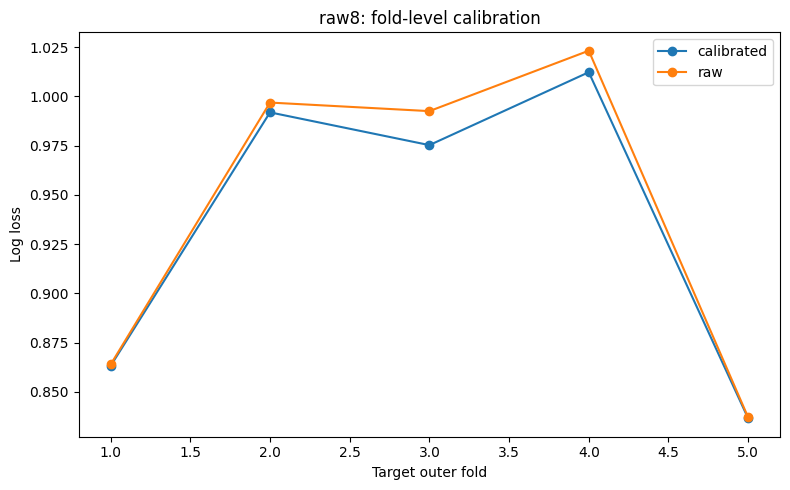

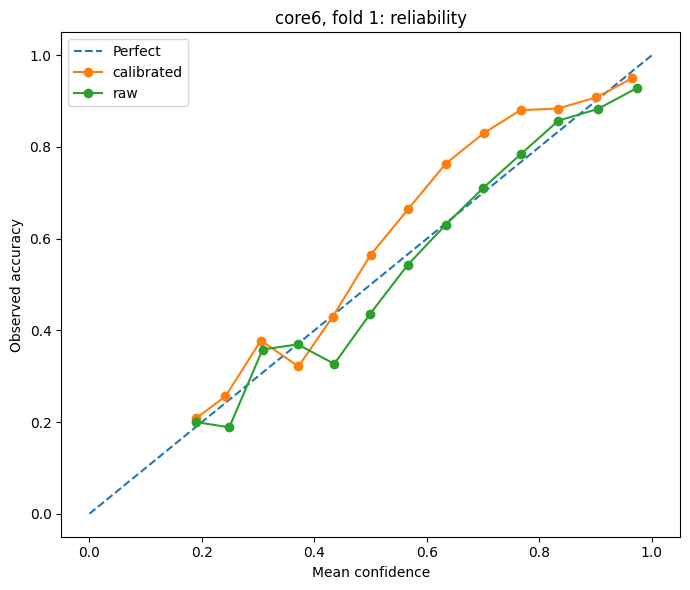

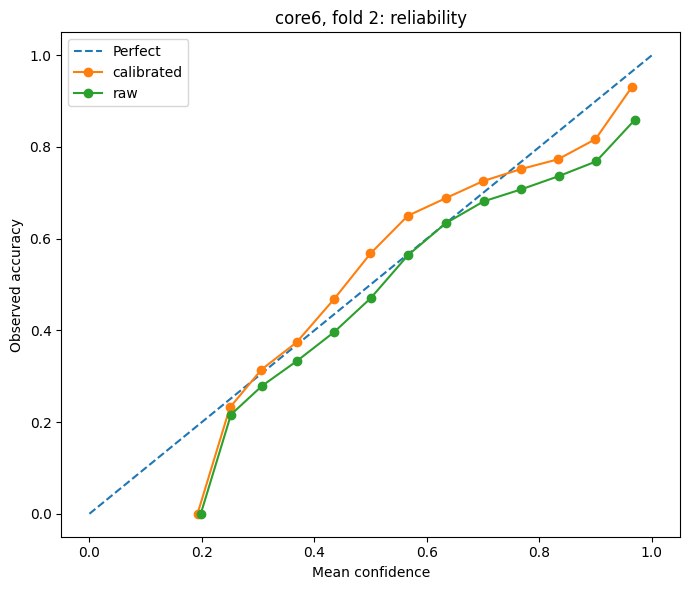

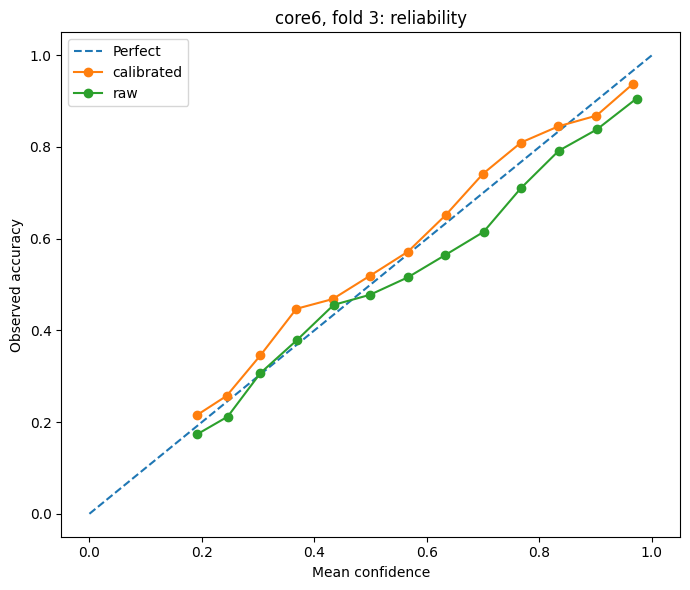

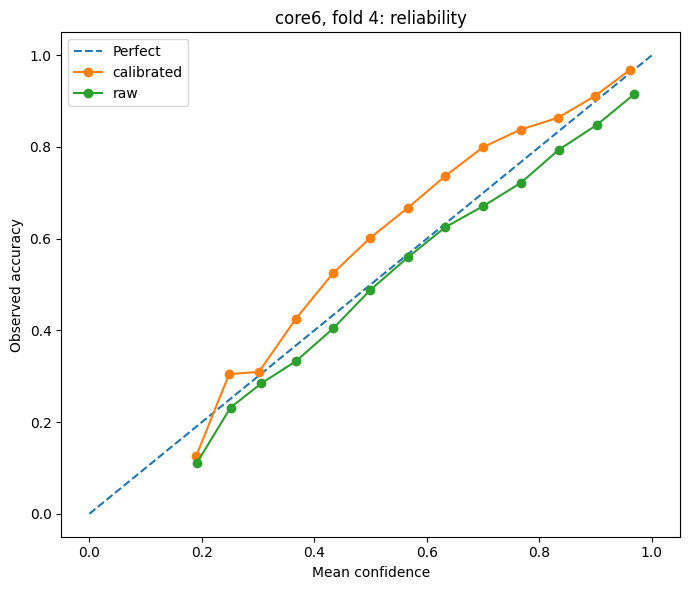

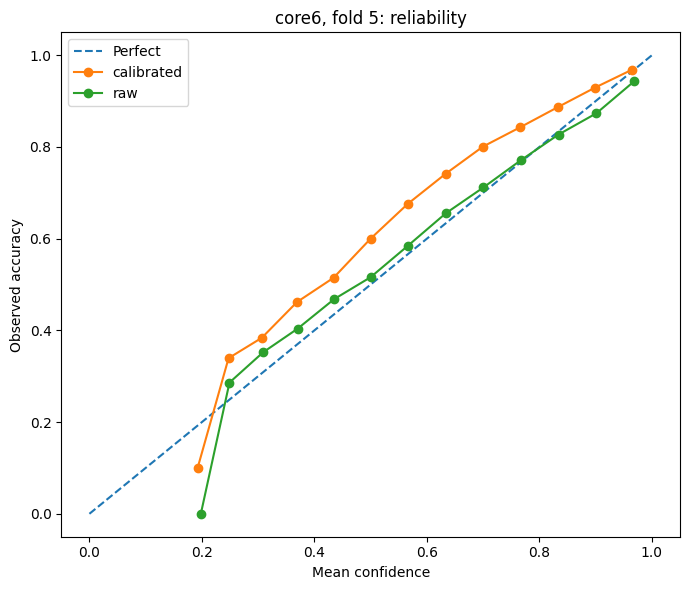

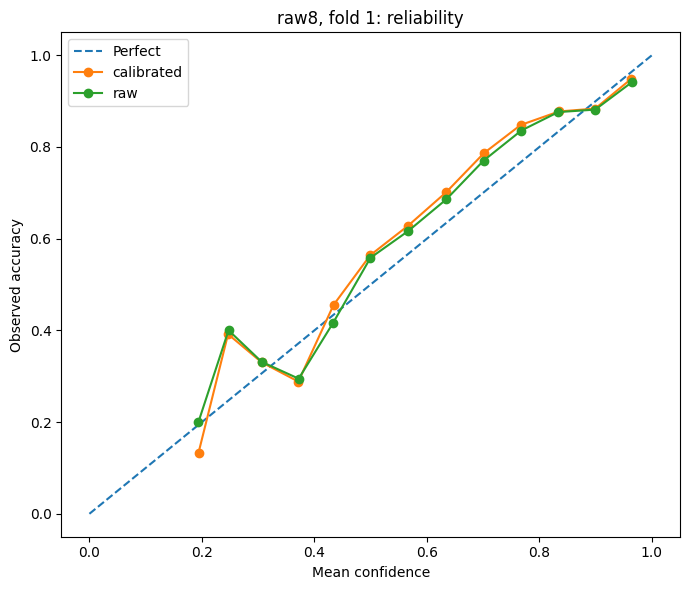

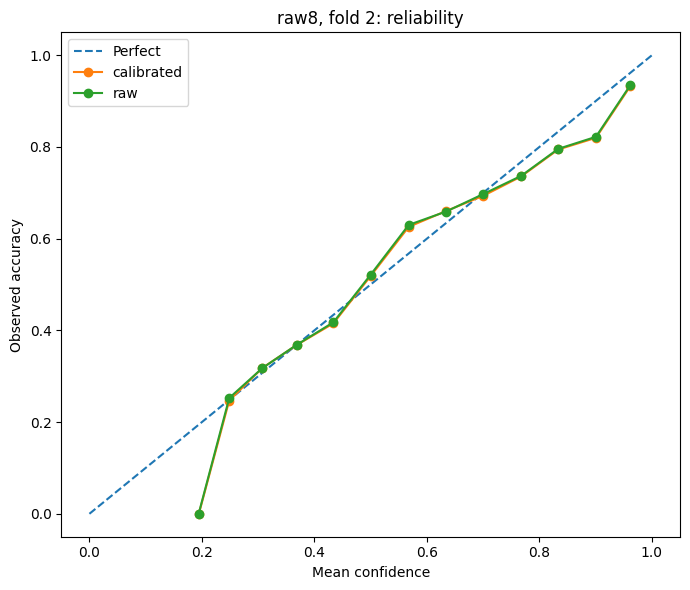

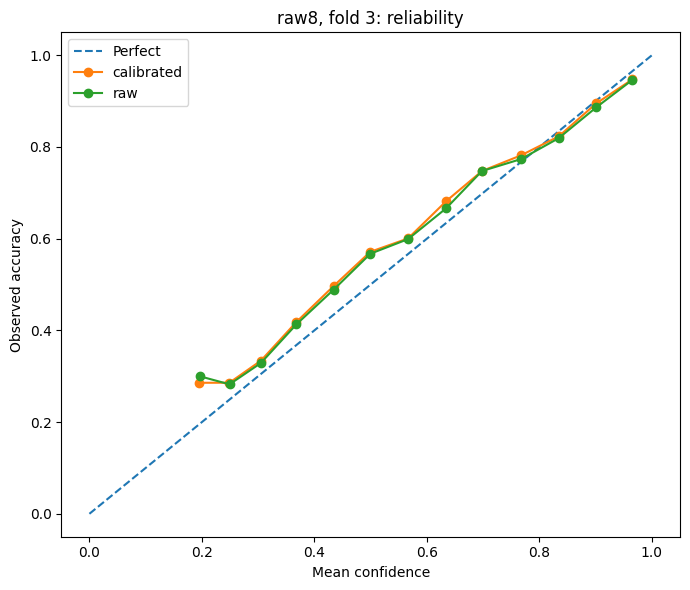

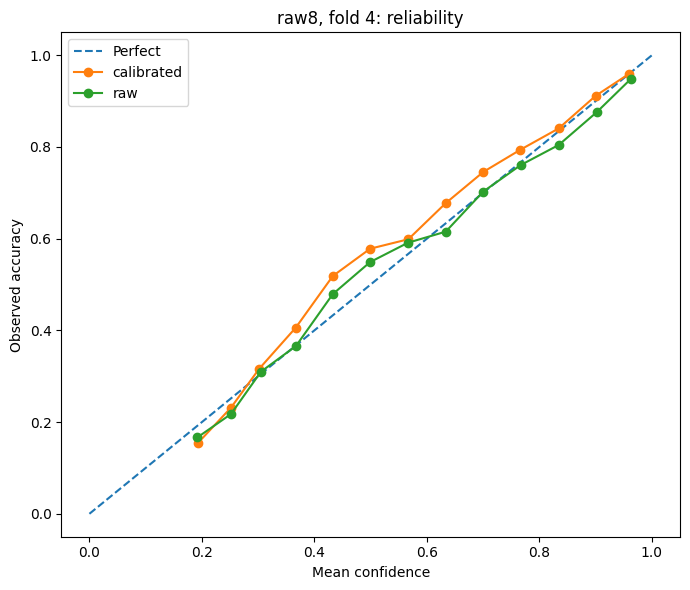

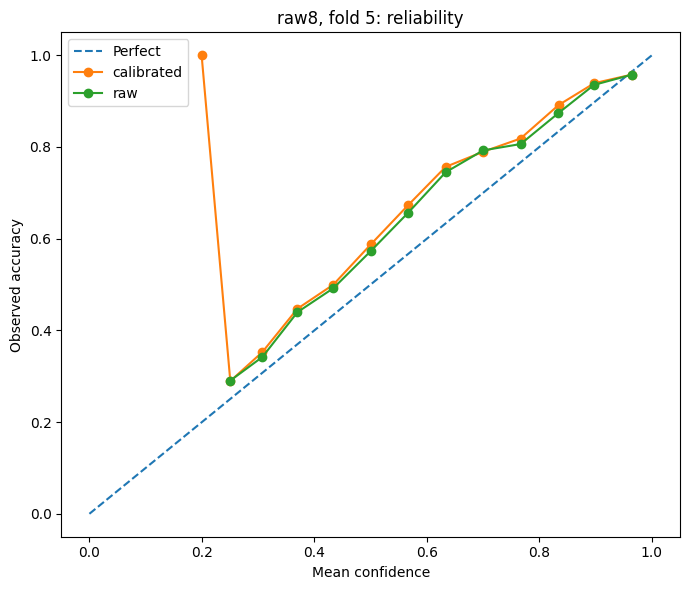

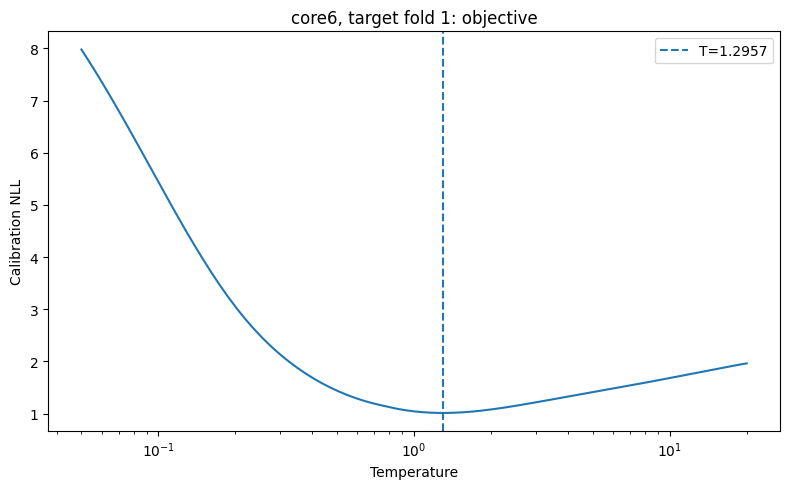

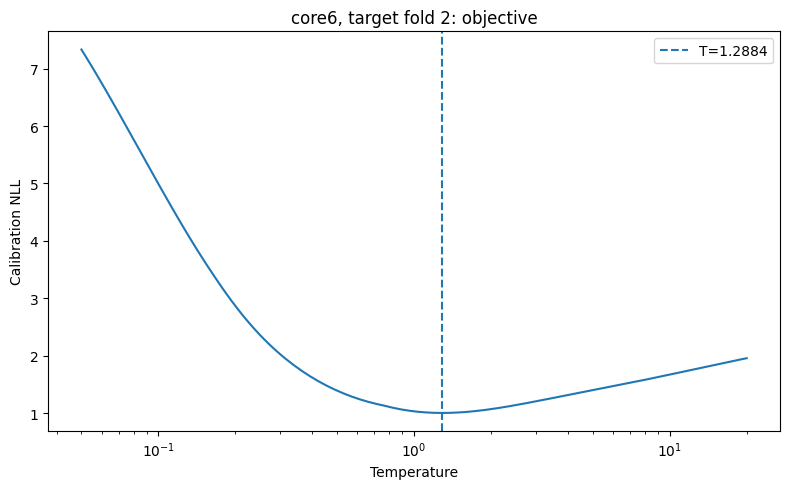

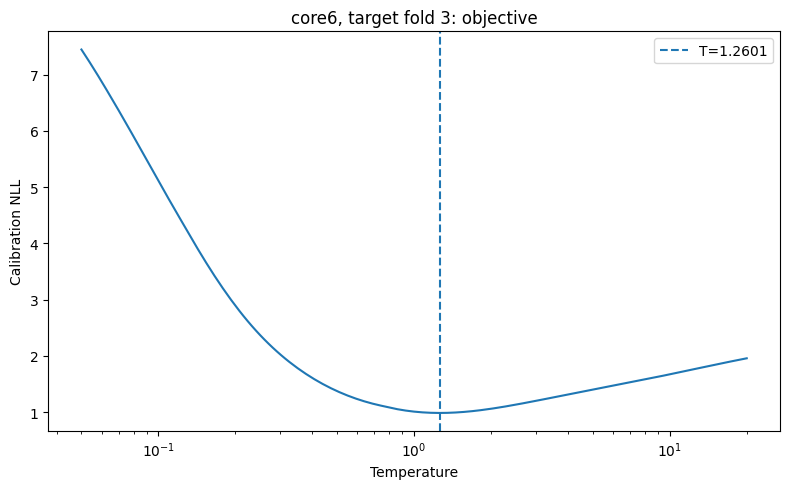

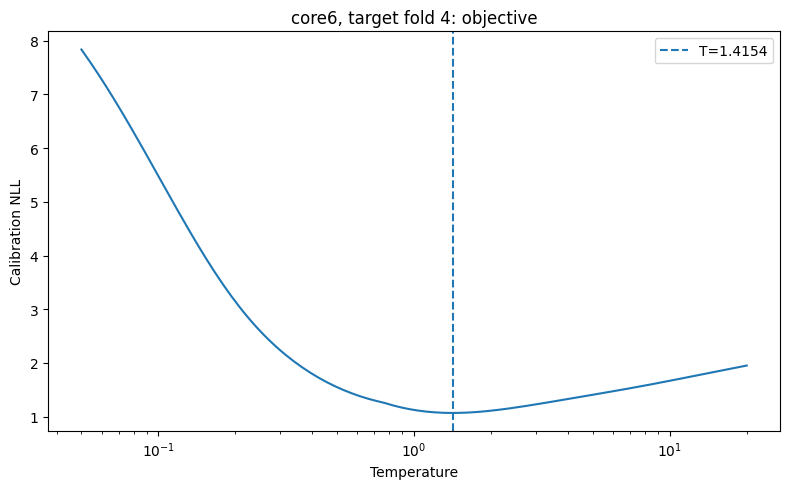

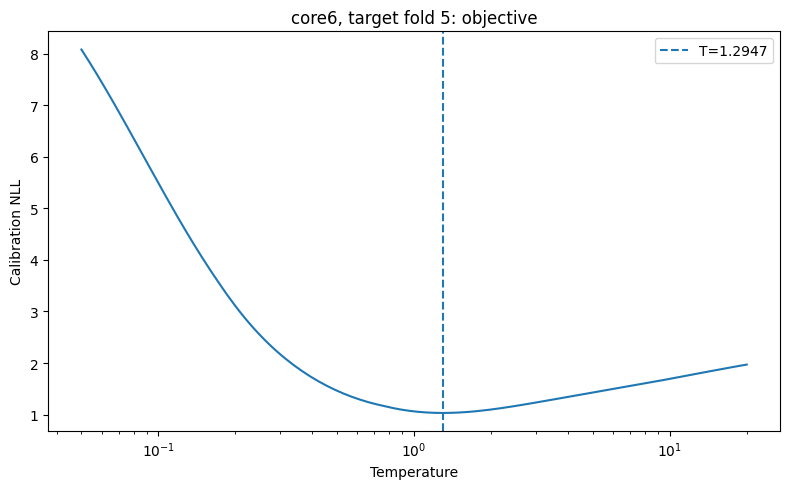

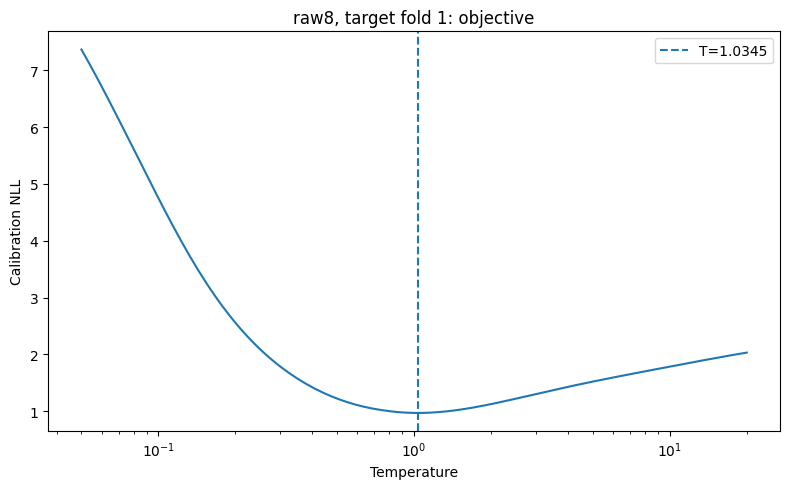

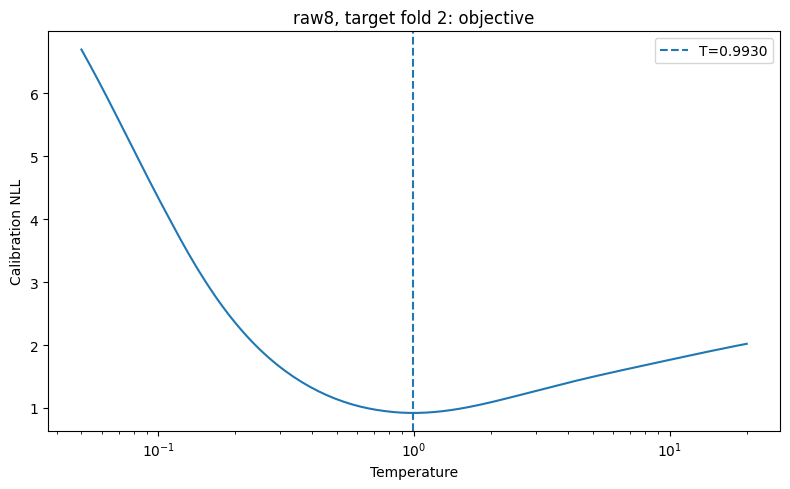

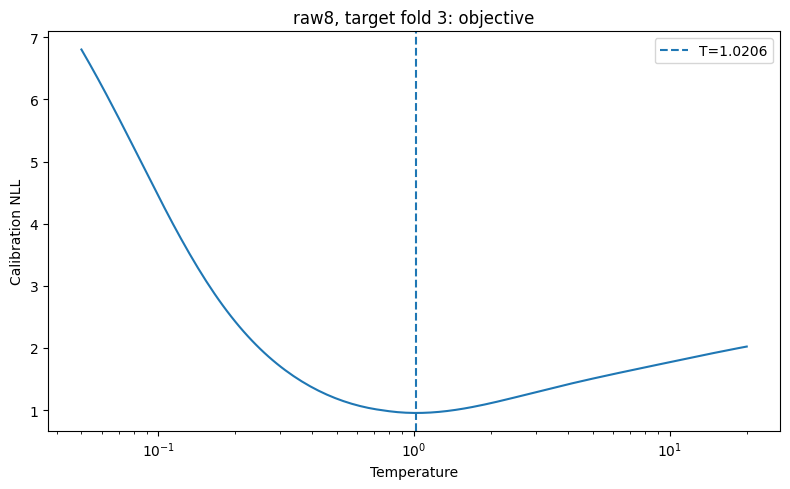

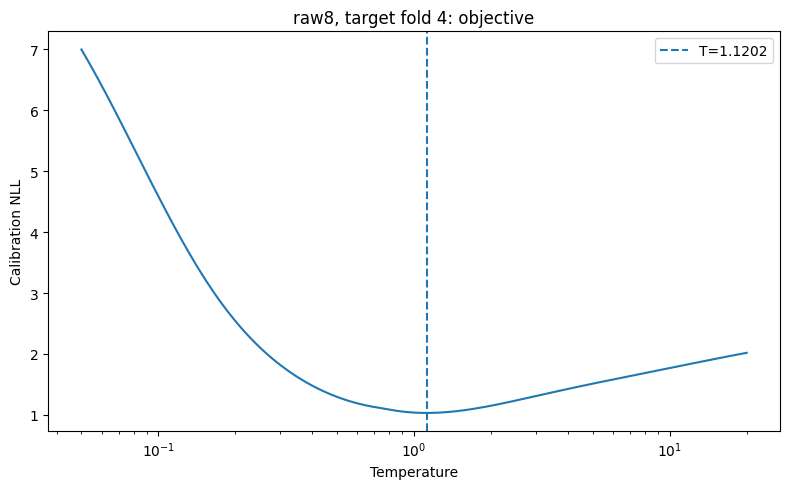

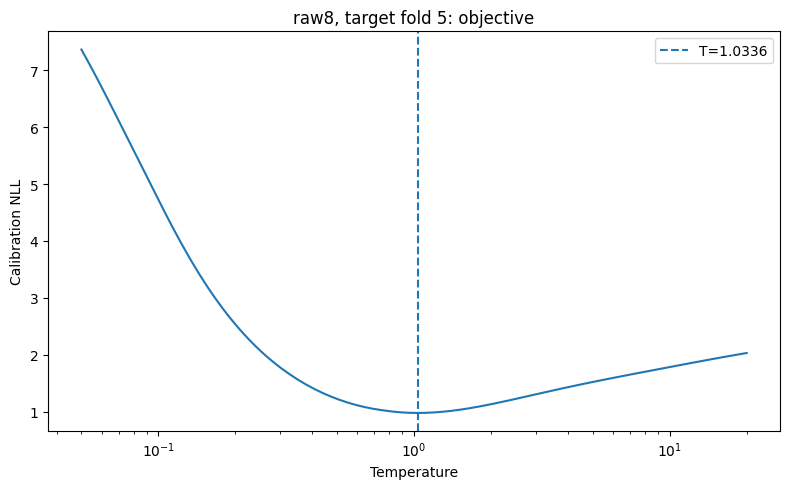

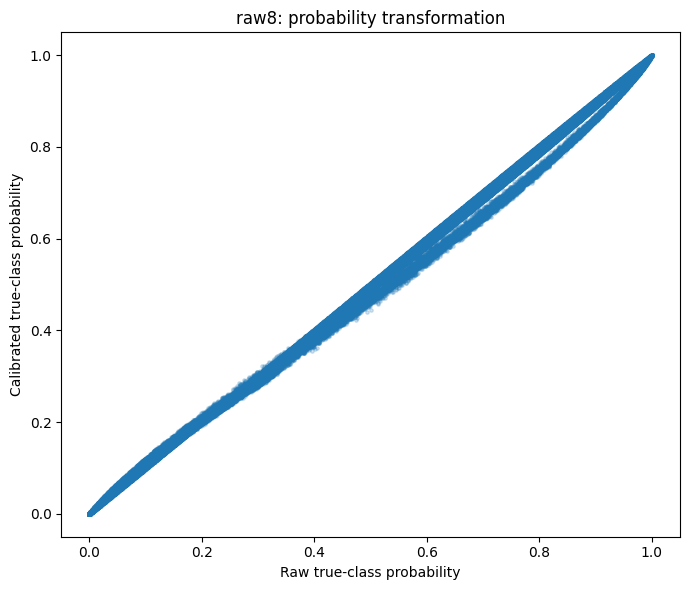

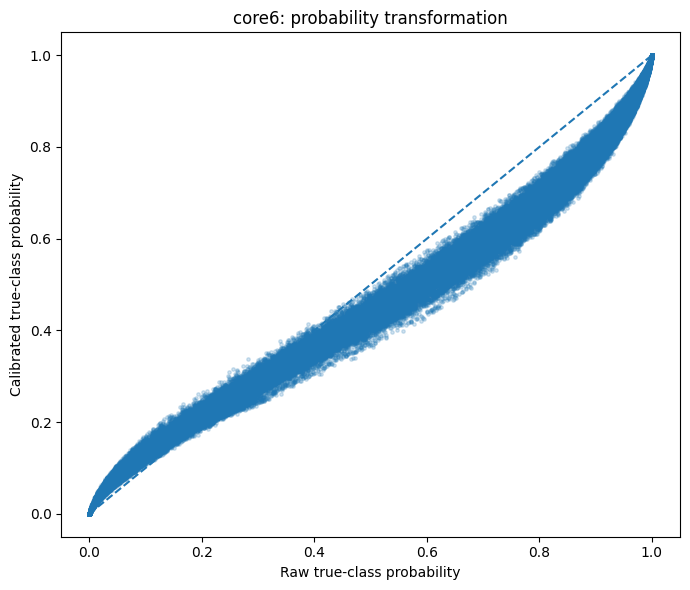

In [11]:
def savefig(name):
    plt.tight_layout()
    plt.savefig(PLOT_DIR/name,dpi=220,bbox_inches='tight')
    plt.show(); plt.close()

for variant,vdf in temperature_df.groupby('model_variant'):
    plt.figure(figsize=(8,5))
    plt.plot(vdf.target_outer_fold,vdf.temperature,marker='o')
    plt.axhline(1,linestyle='--')
    plt.xlabel('Target outer fold'); plt.ylabel('Temperature')
    plt.title(f'{variant}: strict nested temperatures')
    plt.xticks(sorted(vdf.target_outer_fold.unique()))
    savefig(f'01_temperature_by_fold_{variant}.png')

for metric_name in ['log_loss','multiclass_brier','ece_15']:
    for variant,vdf in pooled_df.groupby('model_variant'):
        plt.figure(figsize=(7,5))
        plt.bar(vdf.probability_status,vdf[metric_name])
        plt.ylabel(metric_name); plt.title(f'{variant}: pooled {metric_name}')
        savefig(f'02_pooled_{metric_name}_{variant}.png')

for variant,vdf in fold_metrics_df.groupby('model_variant'):
    p = vdf.pivot(index='target_outer_fold',columns='probability_status',values='log_loss')
    plt.figure(figsize=(8,5))
    for status in p.columns:
        plt.plot(p.index,p[status],marker='o',label=status)
    plt.xlabel('Target outer fold'); plt.ylabel('Log loss'); plt.legend()
    plt.title(f'{variant}: fold-level calibration')
    savefig(f'03_fold_log_loss_{variant}.png')

for (variant,fold),g in reliability_df.groupby(['model_variant','target_outer_fold']):
    plt.figure(figsize=(7,6))
    plt.plot([0,1],[0,1],linestyle='--',label='Perfect')
    for status,s in g.groupby('probability_status'):
        s=s.dropna(subset=['mean_confidence','accuracy'])
        plt.plot(s.mean_confidence,s.accuracy,marker='o',label=status)
    plt.xlabel('Mean confidence'); plt.ylabel('Observed accuracy'); plt.legend()
    plt.title(f'{variant}, fold {fold}: reliability')
    savefig(f'04_reliability_{variant}_fold_{fold}.png')

for (variant,fold),g in objective_df.groupby(['model_variant','target_outer_fold']):
    T=float(temperature_df.loc[(temperature_df.model_variant==variant)&(temperature_df.target_outer_fold==fold),'temperature'].iloc[0])
    plt.figure(figsize=(8,5))
    plt.plot(g.temperature,g.nll)
    plt.axvline(T,linestyle='--',label=f'T={T:.4f}')
    plt.xscale('log'); plt.xlabel('Temperature'); plt.ylabel('Calibration NLL'); plt.legend()
    plt.title(f'{variant}, target fold {fold}: objective')
    savefig(f'05_temperature_objective_{variant}_fold_{fold}.png')

for variant,df in calibrated_oof.items():
    sample=df[['raw_true_class_probability_replayed','calibrated_true_class_probability']]
    if len(sample)>100000:
        sample=sample.sample(100000,random_state=RANDOM_STATE)
    plt.figure(figsize=(7,6))
    plt.scatter(sample.iloc[:,0],sample.iloc[:,1],s=6,alpha=.2)
    plt.plot([0,1],[0,1],linestyle='--')
    plt.xlabel('Raw true-class probability'); plt.ylabel('Calibrated true-class probability')
    plt.title(f'{variant}: probability transformation')
    savefig(f'06_true_probability_raw_vs_calibrated_{variant}.png')

# 10. Stage Gate و ذخیره خروجی‌ها

In [12]:
pair_audit_df = pd.DataFrame(pair_audits)
pair_manifest_df = pd.DataFrame(pair_manifest)
calibration_audit_df = pd.DataFrame(calibration_audits)
expected_pair_artifacts = len(required_pairs)*len(ACTIVE_VARIANTS)

variant_gates = {}
for variant,df in calibrated_oof.items():
    expected_mask=train.GROUP_FOLD.isin(TARGET_FOLDS)
    P=df[[f'cal_prob_{c}' for c in CLASSES]].to_numpy(float)
    variant_gates[variant]={
        'row_count_correct':len(df)==int(expected_mask.sum()),
        'row_ids_unique':not df.ORIGINAL_ROW_ID.duplicated().any(),
        'well_count_correct':df.WELL.nunique()==train.loc[expected_mask,'WELL'].nunique(),
        'target_fold_count_correct':df.outer_fold.nunique()==len(TARGET_FOLDS),
        'probabilities_finite':bool(np.isfinite(P).all()),
        'probabilities_in_range':bool((P>=-1e-8).all() and (P<=1+1e-8).all()),
        'probability_rows_sum_to_one':bool(np.allclose(P.sum(axis=1),1,rtol=1e-6,atol=1e-6)),
        'argmax_unchanged':bool((df.predicted_code==df.calibrated_predicted_code).all()),
    }

stage_gate={
    'official_test_unused':True,
    'stage_05A_passed':bool(gate05a['overall_raw_feature_contract_passed']),
    'stage_05B_passed':bool(gate05b['overall_raw_RF_grouped_CV_passed']),
    'strict_nested_grouped_calibration_used':True,
    'target_outer_fold_excluded_from_temperature_fit':True,
    'inner_validation_fold_excluded_from_predicting_model':True,
    'pair_model_count':len(pair_audit_df),
    'expected_pair_model_count':expected_pair_artifacts,
    'pair_model_count_correct':len(pair_audit_df)==expected_pair_artifacts,
    'all_pair_gates_passed':bool(pair_audit_df.pair_gate_passed.all()),
    'all_calibration_set_gates_passed':bool(calibration_audit_df.calibration_gate_passed.all()),
    'all_temperatures_positive_finite':bool(temperature_df.temperature_positive_finite.all()),
    'all_temperatures_inside_bounds':bool(temperature_df.temperature_inside_bounds.all()),
    'all_optimizations_successful':bool(temperature_df.optimization_success.all()),
    'calibration_set_nll_never_worse':bool(temperature_df.calibration_nll_not_worse.all()),
    'raw_oof_replay_matches_05B':bool(replay_df.true_probability_replay_matches.all() and replay_df.row_log_loss_replay_matches.all()),
    'predicted_labels_and_accuracy_unchanged':bool(replay_df.predicted_labels_unchanged.all() and replay_df.accuracy_unchanged.all()),
    'no_interventions_applied':True,
    'no_outer_target_model_refitting':True,
    'variant_gates':variant_gates,
}
variant_checks=[v for d in variant_gates.values() for v in d.values()]
stage_gate['overall_strict_nested_temperature_calibration_passed']=bool(
    all(v for k,v in stage_gate.items() if k not in ['variant_gates','overall_strict_nested_temperature_calibration_passed'])
    and all(variant_checks)
)
print(json.dumps(stage_gate,indent=2))
if not stage_gate['overall_strict_nested_temperature_calibration_passed']:
    raise RuntimeError('05C stage gate failed.')

pair_audit_df.to_csv(OUT/'00_inner_pair_model_audit.csv',index=False)
pair_manifest_df.to_csv(OUT/'01_inner_pair_artifact_manifest.csv',index=False)
calibration_audit_df.to_csv(OUT/'02_calibration_dataset_audit.csv',index=False)
temperature_df.to_csv(OUT/'03_temperature_registry.csv',index=False)
fold_metrics_df.to_csv(OUT/'04_outer_fold_raw_vs_calibrated_metrics.csv',index=False)
pooled_df.to_csv(OUT/'05_pooled_raw_vs_calibrated_metrics.csv',index=False)
well_df.to_csv(OUT/'06_per_well_raw_vs_calibrated_metrics.csv',index=False)
well_balanced_df.to_csv(OUT/'07_well_balanced_raw_vs_calibrated_metrics.csv',index=False)
replay_df.to_csv(OUT/'08_raw_oof_replay_and_invariance_audit.csv',index=False)
objective_df.to_csv(OUT/'09_temperature_objective_curves.csv',index=False)
reliability_df.to_csv(OUT/'10_reliability_bins.csv',index=False)

temperature_map={v:{str(int(r.target_outer_fold)):float(r.temperature) for _,r in temperature_df.loc[temperature_df.model_variant==v].iterrows()} for v in ACTIVE_VARIANTS}
with open(OUT/'11_temperature_map.json','w',encoding='utf-8') as f:
    json.dump(temperature_map,f,indent=2,ensure_ascii=False)
for variant,df in calibrated_oof.items():
    df.to_parquet(OUT/f'12_calibrated_OOF_predictions_{variant}.parquet',index=False)
with open(OUT/'13_stage_gate.json','w',encoding='utf-8') as f:
    json.dump(stage_gate,f,indent=2,ensure_ascii=False)

run_config={
    'stage':'05C_raw_RF_strict_nested_temperature_calibration',
    'run_mode':RUN_MODE,'source_05B_run_mode':SOURCE_05B_MODE,
    'official_test_used':False,'target_outer_folds':TARGET_FOLDS,
    'active_model_variants':ACTIVE_VARIANTS,'model_variants':MODEL_VARIANTS,
    'rf_hyperparameters':RF_PARAMS,'required_heldout_pairs':[list(p) for p in required_pairs],
    'temperature_bounds':[T_MIN,T_MAX],'probability_epsilon':EPS,'ece_bins':ECE_BINS,
    'temperature_fit_data':'strict inner OOF predictions from outer-training folds only',
    'outer_target_fold_used_in_temperature_fit':False,'interventions_applied':False,
    'inner_models_saved':SAVE_INNER_MODELS,
    'next_stage':'06A_raw_RF_class_conditional_transport_interventions',
    'input_hashes':current_hashes,
}
with open(OUT/'14_run_configuration.json','w',encoding='utf-8') as f:
    json.dump(run_config,f,indent=2,ensure_ascii=False)
with open(OUT/'15_environment.json','w',encoding='utf-8') as f:
    json.dump({'python':platform.python_version(),'platform':platform.platform(),'numpy':np.__version__,'pandas':pd.__version__,'scipy':scipy.__version__,'sklearn':sklearn.__version__,'joblib':joblib.__version__},f,indent=2)

print('\n✅ 05C passed')
print('Outputs:',OUT)

{
  "official_test_unused": true,
  "stage_05A_passed": true,
  "stage_05B_passed": true,
  "strict_nested_grouped_calibration_used": true,
  "target_outer_fold_excluded_from_temperature_fit": true,
  "inner_validation_fold_excluded_from_predicting_model": true,
  "pair_model_count": 20,
  "expected_pair_model_count": 20,
  "pair_model_count_correct": true,
  "all_pair_gates_passed": true,
  "all_calibration_set_gates_passed": true,
  "all_temperatures_positive_finite": true,
  "all_temperatures_inside_bounds": true,
  "all_optimizations_successful": true,
  "calibration_set_nll_never_worse": true,
  "raw_oof_replay_matches_05B": true,
  "predicted_labels_and_accuracy_unchanged": true,
  "no_interventions_applied": true,
  "no_outer_target_model_refitting": true,
  "variant_gates": {
    "raw8": {
      "row_count_correct": true,
      "row_ids_unique": true,
      "well_count_correct": true,
      "target_fold_count_correct": true,
      "probabilities_finite": true,
      "probabilit

# فایل‌هایی که بعد از Pilot ارسال می‌شوند

از مسیر:

```text
${STRATASHIFT_ARTIFACT_ROOT}/
05C_raw_RF_strict_nested_temperature_calibration/pilot
```

این فایل‌ها را ارسال کن:

```text
00_inner_pair_model_audit.csv
02_calibration_dataset_audit.csv
03_temperature_registry.csv
04_outer_fold_raw_vs_calibrated_metrics.csv
05_pooled_raw_vs_calibrated_metrics.csv
07_well_balanced_raw_vs_calibrated_metrics.csv
08_raw_oof_replay_and_invariance_audit.csv
11_temperature_map.json
13_stage_gate.json
14_run_configuration.json
```

Plotهای مهم:

```text
01_temperature_by_fold_raw8.png
02_pooled_log_loss_raw8.png
02_pooled_multiclass_brier_raw8.png
02_pooled_ece_15_raw8.png
03_fold_log_loss_raw8.png
04_reliability_raw8_fold_1.png
05_temperature_objective_raw8_fold_1.png
06_true_probability_raw_vs_calibrated_raw8.png
```

بعد از پاس شدن Pilot:

1. مرحله `05B` را در حالت Full اجرا کن؛
2. در این نوت‌بوک `RUN_MODE = "full"` قرار بده؛
3. `Restart Kernel` و `Run All`.

پس از Full وارد `06A` می‌شویم و برای اولین بار مداخلات بانک `04C` را روی مدل‌های Frozen اعمال می‌کنیم.